Between-group cluster-based permutation analysis for emBODY maps (based on t-test).

Hypothesis: There are significant differences between body maps of **2** different groups of participants.

Workflow:
1. Load subject group assignments from an Excel file.
2. Load emotion-specific body maps from .npz files.
3. Run MNE cluster-based permutation testing between groups.
4. Save cluster statistics and mean maps.
5. Generate visualization figures showing:
   - Mean activation maps for each group
   - Significant positive clusters (black outline)
   - Significant negative clusters (green outline)

Group comparison interpretation:
    Positive cluster: Group 1 > Group 2
    Negative cluster: Group 1 < Group 2

In [1]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.stats import t as t_distribution
from datetime import datetime
from scipy.sparse import lil_matrix
from mne.stats import permutation_cluster_test
import pandas as pd
import subprocess

# ============================================================
# Statistical helper functions
# ============================================================

def safe_welch_t_statistic(*args):
    """
    Approximate Welch t statistic for two groups.
    args[0], args[1] : ndarray, shape (n_subjects_in_group, height, width)
    """
    X, Y = args
    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)

    n1, n2 = X.shape[0], Y.shape[0]

    mean_x = np.mean(X, axis=0)
    mean_y = np.mean(Y, axis=0)

    var_x = np.var(X, axis=0, ddof=1)
    var_y = np.var(Y, axis=0, ddof=1)

    pooled_se = np.sqrt(var_x / n1 + var_y / n2)

    t_values = np.zeros_like(mean_x, dtype=float)

    valid = (
        np.isfinite(mean_x) & np.isfinite(mean_y)
        & np.isfinite(pooled_se) & (pooled_se > 0))

    np.divide(mean_x - mean_y, pooled_se, out=t_values, where=valid)

    return t_values

# ============================================================
# Connectivity matrix construction
# ============================================================

def create_8_connectivity(height, width):
    """
    Create 8-neighbor connectivity for a 2D image.

    Each pixel is connected to:
        up, down, left, right,
        and the four diagonal neighbors.
    """

    n_pixels = height * width

    adjacency = lil_matrix(
        (n_pixels, n_pixels),
        dtype=int,)

    for row in range(height):
        for col in range(width):

            pixel = row * width + col

            for row_offset in [-1, 0, 1]:
                for col_offset in [-1, 0, 1]:

                    # Don't connect a pixel to itself
                    if row_offset == 0 and col_offset == 0:
                        continue

                    neighbor_row = row + row_offset
                    neighbor_col = col + col_offset

                    # Make sure neighbor is inside image
                    if (0 <= neighbor_row < height
                        and 0 <= neighbor_col < width):
                        neighbor = (neighbor_row * width + neighbor_col)
                        adjacency[pixel, neighbor] = 1

    return adjacency.tocsr()

def load_group_lookup(xlsx_path, id_column, group_column):
    """
    Load a subject_id -> group mapping from an Excel file.

    Parameters
    ----------
    xlsx_path : str or Path
        Path to the .xlsx file containing subject IDs and group labels.

    id_column : str
        Column name holding the subject/embody ID.

    group_column : str
        Column name holding the group label (e.g. "group1", "group2").

    Returns
    -------
    group_lookup : dict
        Maps subject_id (str) -> group (str)
    """
    xlsx_path = Path(xlsx_path)

    df = pd.read_excel(xlsx_path)

    if id_column not in df.columns:
        raise ValueError(
            f"Column '{id_column}' not found in {xlsx_path.name}. "
            f"Available columns: {list(df.columns)}")

    if group_column not in df.columns:
        raise ValueError(
            f"Column '{group_column}' not found in {xlsx_path.name}. "
            f"Available columns: {list(df.columns)}")

    # Coerce IDs to string so they match file_path.stem in load_subject_maps_with_groups
    df[id_column] = df[id_column].astype(str).str.strip()
    df[group_column] = df[group_column].astype(str).str.strip()

    duplicate_ids = df[id_column][df[id_column].duplicated()]
    if not duplicate_ids.empty:
        print(f"Warning: duplicate subject IDs found: {duplicate_ids.tolist()}")

    missing_group = df[df[group_column].isin(["", "nan", "None"])]
    if not missing_group.empty:
        print(f"Warning: subjects with missing group assignment: {missing_group[id_column].tolist()}")

    group_lookup = dict(zip(df[id_column], df[group_column]))
    return group_lookup

def load_one_emotion(npz_folder, emotion_index, group_lookup, group_1, group_2):
    npz_folder = Path(npz_folder)
    group1_maps, group2_maps = [], []

    for file_path in sorted(npz_folder.rglob("*.npz")):
        subject_id = file_path.stem
        group = group_lookup.get(subject_id)
        if group not in (group_1, group_2):
            continue

        with np.load(file_path) as saved:
            if "resmat" not in saved:
                continue
            # Each .npz file contains a 3D resmat:
            # (body_height, body_width, emotion_index)
            # Extract only the current emotion to reduce memory usage.
            emotion_map = saved["resmat"][:, :, emotion_index].astype(np.float32)

        if emotion_map.shape != (600, 235):
            continue

        (group1_maps if group == group_1 else group2_maps).append(emotion_map)

    print(f"{group_1}: {len(group1_maps)} subjects")
    print(f"{group_2}: {len(group2_maps)} subjects")

    return np.stack(group1_maps), np.stack(group2_maps)

# ============================================================
# Cluster permutation analysis
# ============================================================

def cluster_permutation_test_two_groups(
    group1_maps,
    group2_maps,
    n_permutations,
    adjacency,
    cluster_alpha=0.01,
    significance_alpha=0.05,
    n_jobs=-1,):

    group1_maps = np.asarray(group1_maps, dtype=float)
    group2_maps = np.asarray(group2_maps, dtype=float)

    # Use the smaller group's degrees of freedom as a conservative
    # approximation when computing the cluster-forming t-threshold.
    df1 = group1_maps.shape[0] - 1
    df2 = group2_maps.shape[0] - 1
    approx_df = min(df1, df2)

    # MNE expects a threshold for creating candidate clusters.
    # Only pixels exceeding this t-value are considered for
    # cluster formation prior to permutation testing.
    t_threshold = t_distribution.ppf(1 - cluster_alpha / 2, df=approx_df)

    (
        observed_t_map,
        clusters,
        cluster_p_values,
        null_distribution,
    ) = permutation_cluster_test(
        [group1_maps, group2_maps],
        threshold=t_threshold,
        n_permutations=n_permutations,
        tail=0,
        stat_fun=safe_welch_t_statistic,
        adjacency=adjacency,
        out_type="mask",
        n_jobs=n_jobs,
        verbose=True,)

    positive_significant_mask = np.zeros(
        observed_t_map.shape,
        dtype=bool,)

    negative_significant_mask = np.zeros(
        observed_t_map.shape,
        dtype=bool,)

    significant_clusters = []

    for cluster_number, (
        cluster_mask,
        corrected_p,
    ) in enumerate(
        zip(clusters, cluster_p_values),
        start=1,):
        cluster_mask = np.asarray(cluster_mask,dtype=bool,)

        cluster_t_values = observed_t_map[cluster_mask]

        if cluster_t_values.size == 0:
            continue

        # Determine whether this cluster reflects Group1 > Group2
        # or Group1 < Group2 based on the mean t-value within the cluster.
        cluster_sign = (
            1
            if np.nanmean(cluster_t_values) > 0
            else -1)

        cluster_mass = np.sum(np.abs(cluster_t_values))

        cluster_result = {
            "number": cluster_number,
            "sign": int(cluster_sign),
            "size": int(np.sum(cluster_mask)),
            "mass": float(cluster_mass),
            "p_value": float(corrected_p),
            "mask": cluster_mask,}

        if corrected_p <= significance_alpha:
            if cluster_sign > 0:
                # Separate masks are maintained for positive and negative effects
                # so they can be visualized using different contour colors.
                positive_significant_mask |= (cluster_mask)
            else:
                negative_significant_mask |= (cluster_mask)

            significant_clusters.append(cluster_result)

    return {
        "t_map": observed_t_map,
        "positive_significant_mask":
            positive_significant_mask,
        "negative_significant_mask":
            negative_significant_mask,
        "significant_clusters":
            significant_clusters,}

# ============================================================
# Analysis across all emotions
# ============================================================

def analyze_all_emotions_two_groups(
    labels,
    n_permutations,
    adjacency,
    group_1,
    group_2,
    group_lookup,
    npz_folder,
    output_folder,
    results_path,
    cluster_alpha=0.01,
    significance_alpha=0.05,
    n_jobs=-1,):

    results_by_emotion = {}
    group_mean_maps={}

    for emotion_index, emotion_name in enumerate(labels):
        print(f"\n{'='*70}\nTwo-group test {emotion_index+1}/{len(labels)}: {emotion_name}\n{'='*70}")

        group1_maps, group2_maps = load_one_emotion(
        npz_folder, emotion_index, group_lookup, group_1, group_2)

        emotion_results = cluster_permutation_test_two_groups(
            group1_maps=group1_maps,
            group2_maps=group2_maps,
            n_permutations=n_permutations,
            adjacency=adjacency,
            cluster_alpha=cluster_alpha,
            significance_alpha=significance_alpha,
            n_jobs=n_jobs,)

        results_by_emotion[emotion_name] = emotion_results

        print(
            f"{emotion_name}: "
            f"{len(emotion_results['significant_clusters'])} "
            "significant clusters")

        for cluster in emotion_results["significant_clusters"]:
            direction = (
                f"{group_1} > {group_2}"
                if cluster["sign"] > 0
                else f"{group_1} < {group_2}")

            print(
                f"  Cluster {cluster['number']}: "
                f"{direction}, "
                f"size={cluster['size']} pixels, "
                f"mass={cluster['mass']:.2f}, "
                f"corrected p={cluster['p_value']:.4f}")

        group_mean_maps[emotion_name] = (
            np.nanmean(group1_maps, axis=0),
            np.nanmean(group2_maps, axis=0),)

        del group1_maps, group2_maps

        cluster_rows = []

        for cluster in emotion_results["significant_clusters"]:
            direction = (
                f"{group_1} > {group_2}"
                if cluster["sign"] > 0
                else f"{group_1} < {group_2}")

            cluster_rows.append({
                "emotion": emotion_name,
                "cluster_number": cluster["number"],
                "direction": direction,
                "sign": cluster["sign"],
                "size_pixels": cluster["size"],
                "cluster_mass": cluster["mass"],
                "corrected_p_value": cluster["p_value"],
                "significance_alpha": significance_alpha,})

        with open(results_path,"a",newline="",encoding="utf-8") as csv_file:
            writer = csv.DictWriter(csv_file,fieldnames=[
                "emotion",
                "cluster_number",
                "direction",
                "sign",
                "size_pixels",
                "cluster_mass",
                "corrected_p_value",
                "significance_alpha",])
            writer.writerows(cluster_rows)

        output_path = output_folder / (f"cluster_analysis_{emotion_name}.npz")

        np.savez_compressed(
        output_path,
        t_maps=emotion_results["t_map"],
        positive_significant_mask=emotion_results["positive_significant_mask"],
        negative_significant_mask=emotion_results["negative_significant_mask"],
        group1_mean=group_mean_maps[emotion_name][0],
        group2_mean=group_mean_maps[emotion_name][1],
        )

    return results_by_emotion,group_mean_maps

# ============================================================
# Visualization
# ============================================================

def visualize_two_group_cluster_results(
    group_mean_maps, results_by_emotion, base_image_path, labels,
    group_1, group_2, plot_columns=8,):

    base_image = np.asarray(Image.open(base_image_path).convert("RGB"))
    base_crop = base_image[:, LEFT_X1:LEFT_X2, :]

    maximum = max(np.nanmax(np.abs(m)) for name in labels for m in group_mean_maps[name])
    if not np.isfinite(maximum) or maximum == 0:
        maximum = 1

    n_emotions = len(labels)

    pairs_per_row = plot_columns // 2
    plot_rows = int(np.ceil(n_emotions / pairs_per_row))
    fig, axes = plt.subplots(
        plot_rows, plot_columns,
        figsize=(2 * plot_columns, 5 * plot_rows),
        constrained_layout=False,)

    axes = np.atleast_2d(axes)
    heatmap = None

    row_tops = {}

    for row in range(plot_rows):
        row_tops[row] = max(
            axes[row, col].get_position().y1
            for col in range(plot_columns))

    for emotion_index, emotion_name in enumerate(labels):
        results = results_by_emotion[emotion_name]
        mean1, mean2 = group_mean_maps[emotion_name]

        pair_row = emotion_index // pairs_per_row
        pair_col = emotion_index % pairs_per_row

        left_col = pair_col * 2
        right_col = left_col + 1

        left_ax = axes[pair_row, left_col]
        right_ax = axes[pair_row, right_col]

        for axis, group_name, mean_map in [
        (left_ax, group_1, mean1),
        (right_ax, group_2, mean2),]:

            axis.imshow(base_crop)

            heatmap = axis.imshow(
                mean_map,
                cmap="seismic",
                vmin=-maximum,
                vmax=maximum,
                alpha=0.65,
                interpolation="nearest",)

            if np.any(results["positive_significant_mask"]):
                axis.contour(
                    results["positive_significant_mask"].astype(float),
                    levels=[0.5],
                    colors=["black"],
                    linewidths=1.5,
                    linestyles="dashed",)

            if np.any(results["negative_significant_mask"]):
                axis.contour(
                    results["negative_significant_mask"].astype(float),
                    levels=[0.5],
                    colors=["green"],
                    linewidths=1.5,
                    linestyles="dashed",)

            axis.axis("off")

        left_ax.set_title(group_1, fontsize=9)
        right_ax.set_title(group_2, fontsize=9)

        bbox1 = left_ax.get_position()
        bbox2 = right_ax.get_position()

        x_center = (bbox1.x0 + bbox2.x1) / 2
        y_top = row_tops[pair_row]

        fig.text(
            x_center,
            y_top + 0.015,
            f"{emotion_name}: {len(results['significant_clusters'])} clusters",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",)

    used_axes = 2 * len(labels)

    for axis in axes.ravel()[used_axes:]:
        axis.axis("off")

    cbar_ax = fig.add_axes([0.95, 0.25, 0.015, 0.5])

    fig.colorbar(
        heatmap,
        cax=cbar_ax,
        label="Mean activation intensity",)

    fig.suptitle(
        f"{group_1} and {group_2} Comparison Maps with Significant Clusters\n"
        f"(Black = {group_1} > {group_2}; Green = {group_1} < {group_2})",
        fontsize=16)

    fig.subplots_adjust(
        right=0.9,
        wspace=0.25,)

    plt.show()

    return fig

Change below

In [2]:
# Make sure it is same size used when creating resmat.
# Python excludes the ending index, so this crop is 235 pixels wide.
LEFT_X1 = 0
LEFT_X2 = 235

npz_folder = Path(
    "/Users/bb/Documents/Park lab/Embody/Preprocessed/In person")

group_path = Path("/Users/bb/Documents/Park lab/Embody/Demographics/emBODY in-person demographics 9.22.26.xlsx")

base_image_path = Path(
    "/Users/bb/Documents/Park lab/Embody/base.png")

output_folder = Path(
    "/Users/bb/Documents/Park lab/Embody/Results/test")

output_folder.mkdir(parents=True, exist_ok=True)

run_timestamp = datetime.now().strftime("%Y%m%d_%H%M")

results_path = output_folder / (
    f"clusters_analysis_{run_timestamp}.csv")

LABELS = [
    'Neutral',
    'Fear',
    'Anger',
    'Disgust',
    'Sadness',
    'Happiness',
    'Anxiety',
    'Love',
    'Depression',
    'Pride',
    'Shame',]

n_permutations=1000

# Bonferroni correction across all tested emotions.
# Family-wise alpha = 0.05.
significance_alpha = 0.05/len(LABELS)

group_1="Control"
group_2="SZ"

Run below


Two-group test 1/11: Neutral
Control: 201 subjects
SZ: 73 subjects
stat_fun(H1): min=-2.744404797567498 max=2.8321713707138056
Running initial clustering …
Found 4 clusters


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| Permuting : 999/999 [02:40<00:00,    6.23it/s]


Neutral: 0 significant clusters

Two-group test 2/11: Fear
Control: 201 subjects
SZ: 73 subjects
stat_fun(H1): min=-2.6399497023127916 max=3.8418455729422685
Running initial clustering …
Found 9 clusters


100%|██████████| Permuting : 999/999 [02:15<00:00,    7.35it/s]


Fear: 0 significant clusters

Two-group test 3/11: Anger
Control: 201 subjects
SZ: 73 subjects
stat_fun(H1): min=-2.0926176272787176 max=4.642032164628499
Running initial clustering …
Found 33 clusters


...

Depression: 2 significant clusters
  Cluster 2: Control < SZ, size=1002 pixels, mass=3228.42, corrected p=0.0040
  Cluster 25: Control < SZ, size=4461 pixels, mass=15003.56, corrected p=0.0010

Two-group test 10/11: Pride
Control: 201 subjects
SZ: 73 subjects
stat_fun(H1): min=-2.0529238129762386 max=4.296801263065758
Running initial clustering …
Found 13 clusters


100%|██████████| Permuting : 999/999 [01:03<00:00,   15.85it/s]


Pride: 0 significant clusters

Two-group test 11/11: Shame
Control: 201 subjects
SZ: 73 subjects
stat_fun(H1): min=-2.787821852525879 max=3.758454109091365
Running initial clustering …
Found 9 clusters


100%|██████████| Permuting : 999/999 [01:31<00:00,   10.95it/s]


Shame: 0 significant clusters


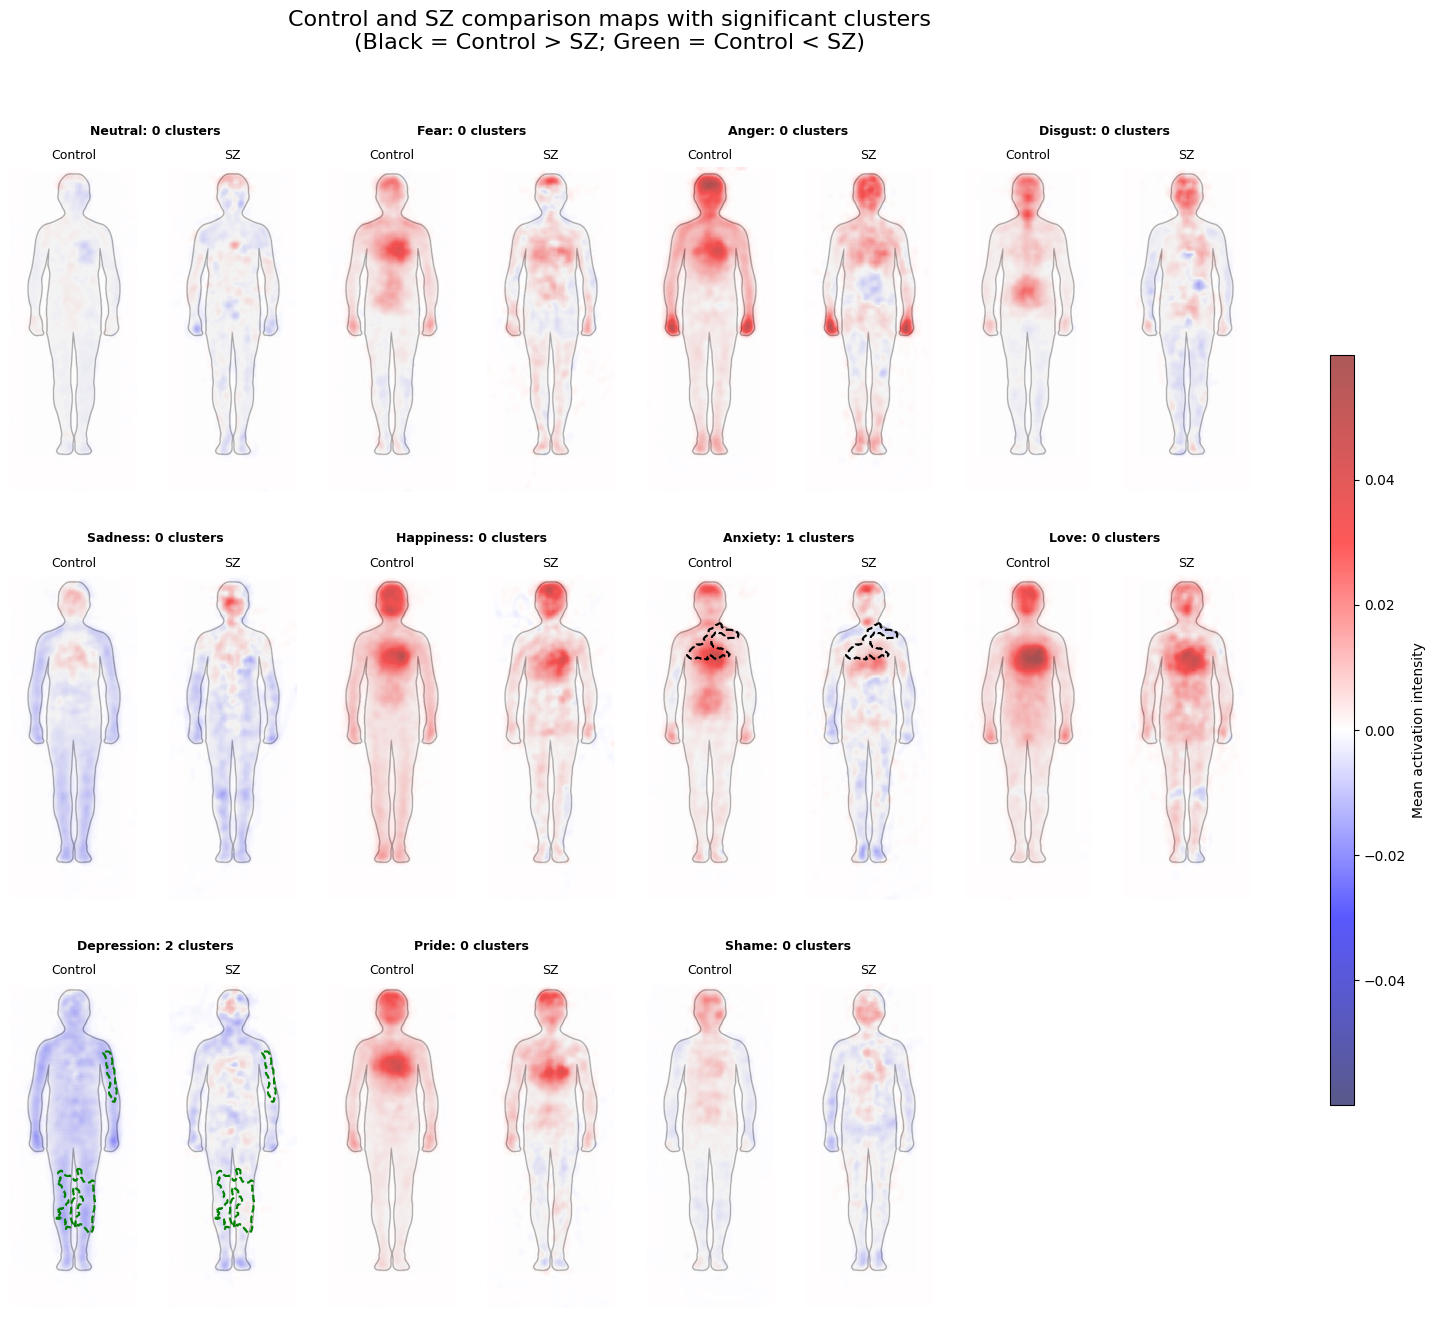

In [3]:
# Start caffeinate in the background
caffeinate_proc = subprocess.Popen(['caffeinate', '-i'])

group_lookup = load_group_lookup(
    group_path,
    id_column="Embody_id",
    group_column="Diagnosis",)

adjacency = create_8_connectivity(600, 235)

with open(results_path,"w",newline="",encoding="utf-8") as csv_file:

    writer = csv.DictWriter(
                csv_file,
                fieldnames=[
                    "emotion",
                    "cluster_number",
                    "direction",
                    "sign",
                    "size_pixels",
                    "cluster_mass",
                    "corrected_p_value",
                    "significance_alpha",])

    writer.writeheader()

results_by_emotion,group_mean_maps = analyze_all_emotions_two_groups(
    labels=LABELS,
    n_permutations=n_permutations,
    adjacency=adjacency,
    cluster_alpha=0.01,
    significance_alpha=significance_alpha,
    n_jobs=-1,
    group_1=group_1,
    group_2=group_2,
    npz_folder=npz_folder,
    group_lookup=group_lookup,
    output_folder=output_folder,
    results_path=results_path)

fig = visualize_two_group_cluster_results(
    group_mean_maps=group_mean_maps,
    results_by_emotion=results_by_emotion,
    base_image_path=base_image_path,
    labels=LABELS,
    group_1=group_1,
    group_2=group_2,)

caffeinate_proc.terminate()